### 1.0.1 1. Import the necessary libraries

In [61]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import warnings
warnings.filterwarnings("ignore")

### 1.0.2 2. Loading and Exploration

In [62]:
df = sns.load_dataset("titanic")

print(df.shape)
df.head()

(891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [63]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [64]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [65]:
categ = df.select_dtypes(include = "object").columns
df[categ].describe()

,sex,embarked,who,embark_town,alive
count,891,889,891,889,891
unique,2,3,3,3,2
top,male,S,man,Southampton,no
freq,577,644,537,644,549


In [74]:
# заменить table

# df.drop(columns = ["deck"], inplace = True)
# df = df.drop(columns = ["deck"])

In [78]:
df_clean = df.drop(columns = ["deck"])

# fill with average
medianAge = df["age"].median()
df["age"].fillna(medianAge, inplace = True)

In [96]:
# fill embarked with mode

modeEmbarked = df["embarked"].mode()[0]
df["embarked"].fillna(modeEmbarked, inplace = True)

In [97]:
# fill embark_town with mode

modeEmbarkTown = df["embark_town"].mode()[0]
df["embark_town"].fillna(modeEmbarkTown, inplace = True)

In [101]:
print(df_clean.isnull().sum())

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       2
class          0
who            0
adult_male     0
embark_town    2
alive          0
alone          0
dtype: int64


In [111]:
# Convert to categorical for memory and plotting

categ =  ['sex', 'embarked', 'class', 'who', 'adult_male', 'alone']
for col in categ:
    df_clean[col] = df_clean[col].astype("category")

df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    category
 3   age          891 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    category
 8   class        891 non-null    category
 9   who          891 non-null    category
 10  adult_male   891 non-null    category
 11  embark_town  889 non-null    object  
 12  alive        891 non-null    object  
 13  alone        891 non-null    category
dtypes: category(6), float64(2), int64(4), object(2)
memory usage: 61.7+ KB


In [118]:
# Remove exact duplicates 

df_clean.drop_duplicates(inplace = True)

In [122]:
# Drop redundant columns

df_clean.drop( columns=['alive', 'pclass', 'embark_town'], inplace = True, errors = "ignore" )

In [123]:
df_clean.head()

,survived,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,alone
0,0,male,22.0,1,0,7.2500,S,Third,man,True,False
1,1,female,38.0,1,0,71.2833,C,First,woman,False,False
2,1,female,26.0,0,0,7.9250,S,Third,woman,False,True
3,1,female,35.0,1,0,53.1000,S,First,woman,False,False
4,0,male,35.0,0,0,8.0500,S,Third,man,True,True


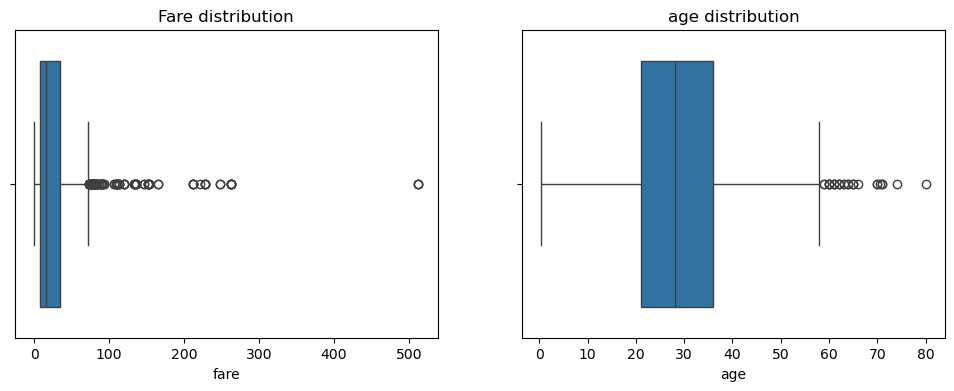

In [153]:
# fare and age distribution

plt.figure(figsize = (12,4))

plt.subplot(1,2,1)
sns.boxplot(x = df_clean["fare"])
plt.title("Fare distribution")

plt.subplot(1,2,2)
sns.boxplot(x = df_clean["age"])
plt.title("age distribution")

plt.show()

In [166]:
# Optional: Cap extreme fares using IQR method

Q1 = df_clean["fare"].quantile(0.25)
Q3 = df_clean["fare"].quantile(0.75)
IQR = Q3 - Q1
upper = Q3 + 1.5*IQR
lower = Q1 - 1.5*IQR

print(upper)

73.41975000000001


Text(0.5, 1.0, 'fare')

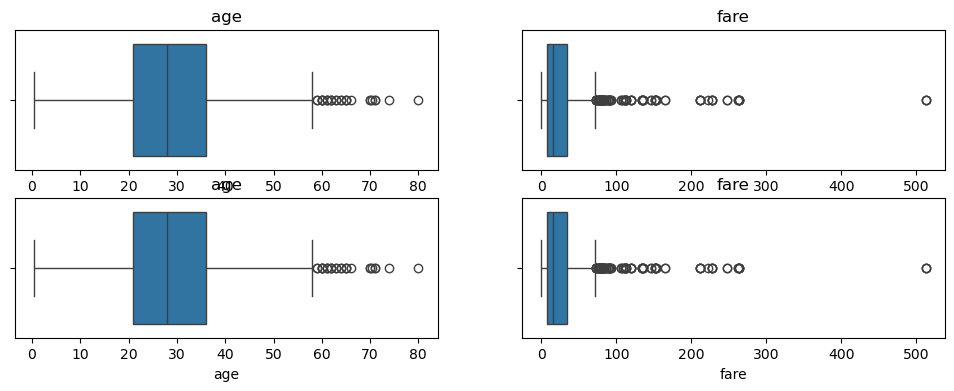

In [236]:
plt.figure(figsize = (12,4))

plt.subplot(2,2,1)
sns.boxplot(x = "age", data = df_clean)
plt.title("age")
plt.subplot(2,2,2)
sns.boxplot(x = "fare", data = df_clean)
plt.title("fare")
plt.subplot(2,2,3)
sns.boxplot(x = "age", data = df_clean)
plt.title("age")
plt.subplot(2,2,4)
sns.boxplot(x = "fare", data = df_clean)
plt.title("fare")

Text(0.5, 1.0, 'age')

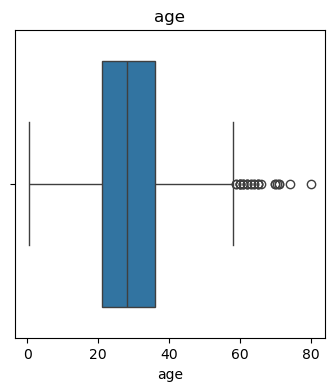

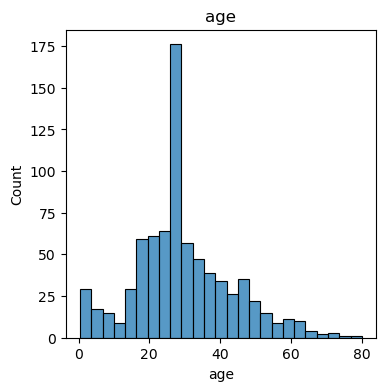

In [237]:
plt.figure(figsize = (4,4))

plt.subplot(1,1,1)
sns.boxplot(x = "age", data = df_clean)
plt.title("age")

plt.figure(figsize = (4,4))
plt.subplot(1,1,1)
sns.histplot(x = "age", data = df_clean)
plt.title("age")



Text(0.5, 1.0, 'survived')

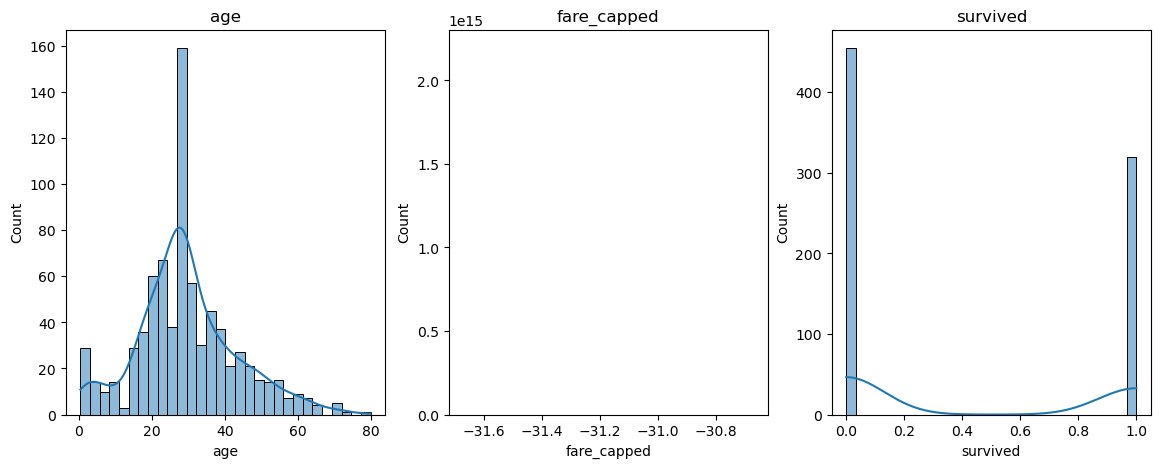

In [238]:
plt.figure(figsize = (14,5))

plt.subplot(1,3,1)
sns.histplot(x = "age", data = df_clean, bins = 30, kde = True)
plt.title("age")

plt.subplot(1,3,2)
sns.histplot(x = "fare_capped", data = df_clean, bins = 30, kde = True)
plt.title("fare_capped")

plt.subplot(1,3,3)
sns.histplot(x = "survived", data = df_clean, bins = 30, kde = True)
plt.title("survived")

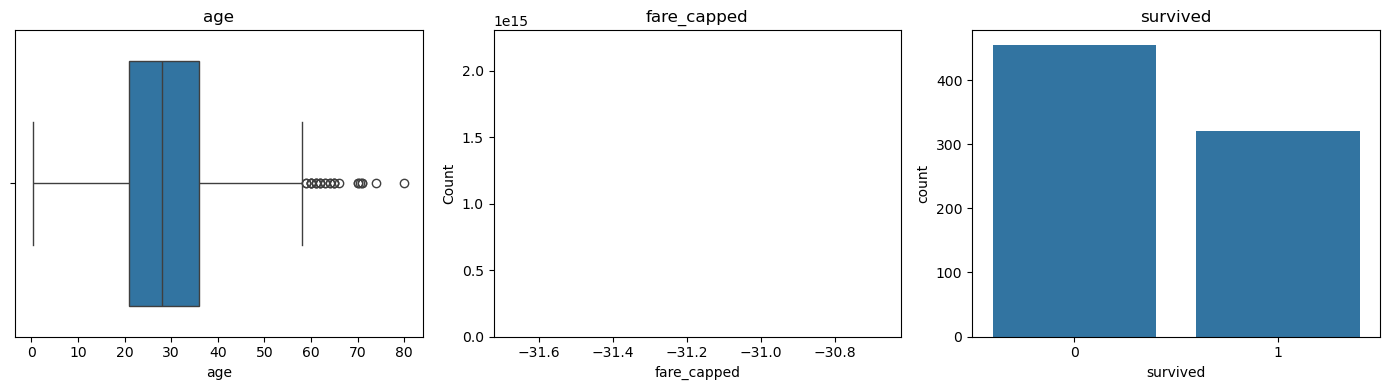

In [239]:
plt.figure(figsize = (14,4))

plt.subplot(1,3,1)
sns.boxplot(x = "age", data = df_clean)
plt.title("age")

plt.subplot(1,3,2)
sns.histplot(x = "fare_capped", kde = True, bins = 30, data = df_clean)
plt.title("fare_capped")

plt.subplot(1,3,3)
sns.countplot(x = "survived", data = df_clean)
plt.title("survived")

plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'lkswd')

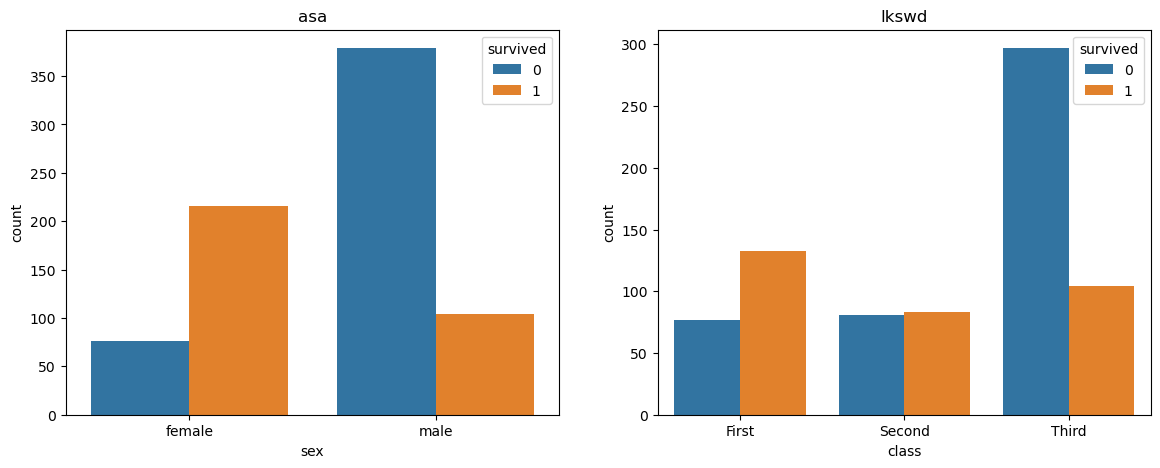

In [240]:
plt.figure(figsize = (14,5))

plt.subplot(1,2,1)
sns.countplot(x = "sex", hue = "survived", data = df_clean)
plt.title("asa")

plt.subplot(1,2,2)
sns.countplot(x = "class", hue = "survived", data = df_clean)
plt.title("lkswd")

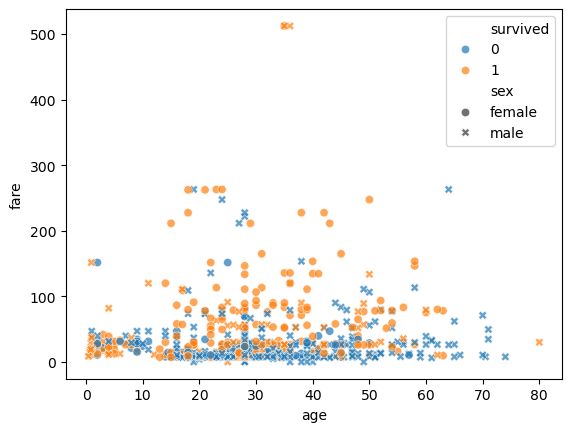

In [241]:
sns.scatterplot(x = "age", y = "fare", data = df_clean, hue = "survived", style = "sex", alpha = 0.7)
plt.show()

<Axes: xlabel='class', ylabel='age'>

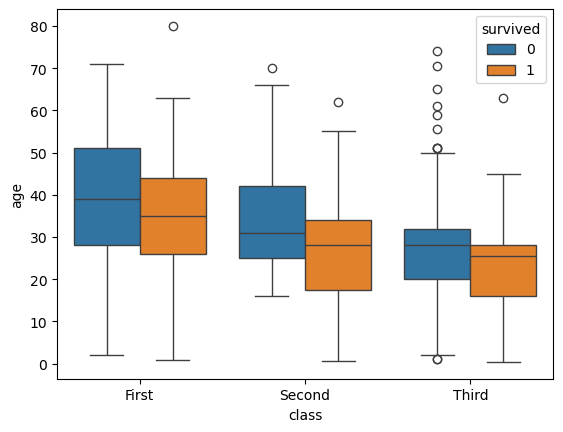

In [242]:
sns.boxplot(x = "class", y = "age", hue = "survived", data = df_clean)

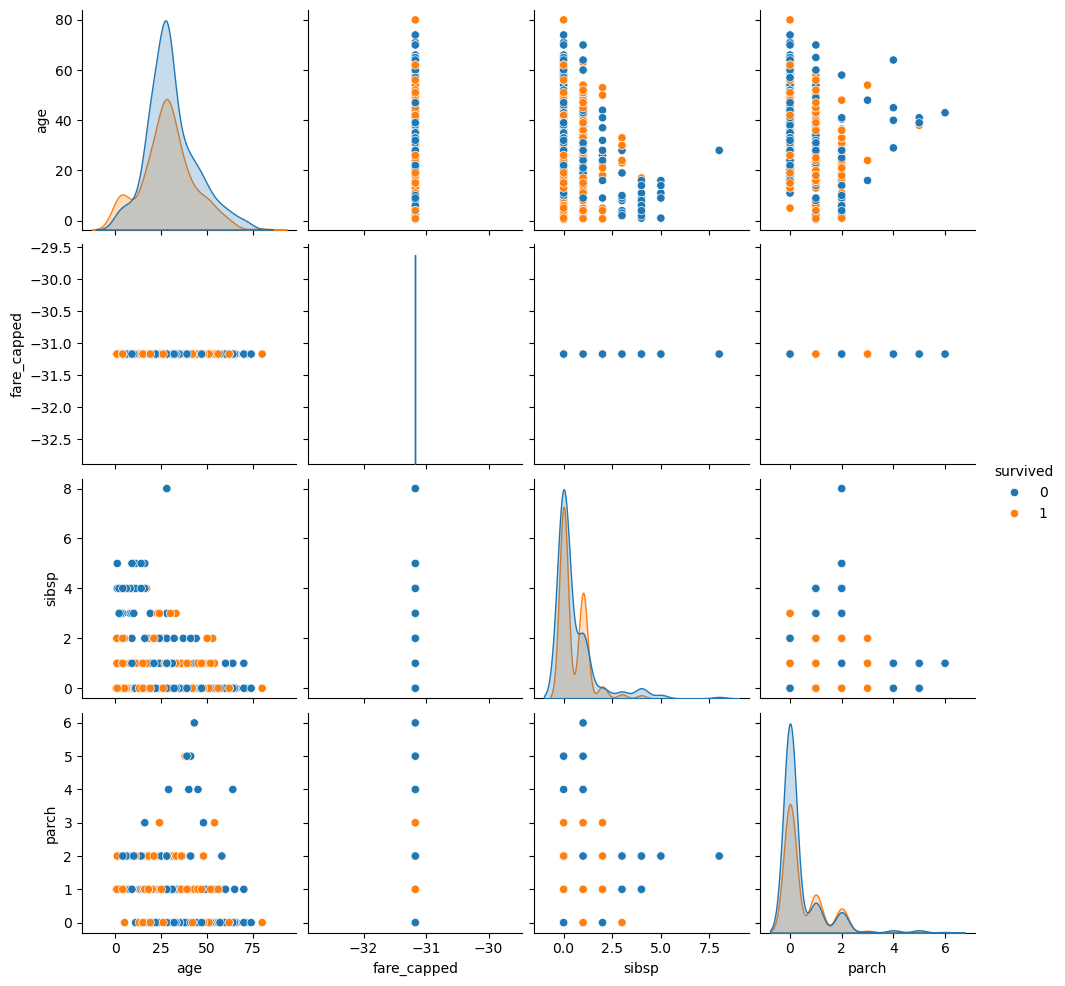

In [245]:
sns.pairplot(data = df_clean, vars=['age', 'fare_capped', 'sibsp', 'parch'], diag_kind = "kde", hue = "survived")
plt.show()

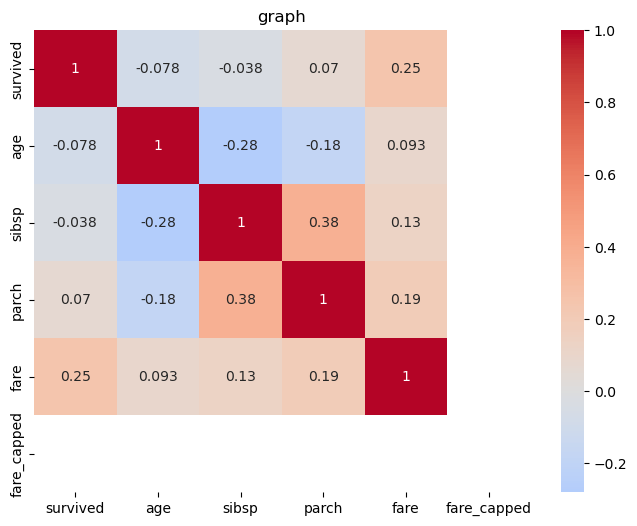

In [253]:
plt.figure(figsize = (8,6))

categ = df_clean.select_dtypes(include = np.number).columns
sns.heatmap(df_clean[categ].corr(), annot = True, center = 0, cmap = "coolwarm")
plt.title("graph")
plt.show()

In [29]:
# basic info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [30]:
# summary
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [32]:
# categorical summary
df.describe(include=["object", "category"])

,sex,embarked,class,who,deck,embark_town,alive
count,891,889,891,891,203,889,891
unique,2,3,3,3,7,3,2
top,male,S,Third,man,C,Southampton,no
freq,577,644,491,537,59,644,549


In [33]:
# check for missing value
print(df.isnull().sum())

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


In [34]:
# check for duplicates
print(df.duplicated().sum())

107


### 1.1 Data Cleaning

#### Common issues in Titanic: - Missing values: age (177), embarked (2), deck (688), embtown (not useful) - Data types: some could be categorical - Outliers - Redundant/unuseful columns

### 1.1.1 Handling Missing Values

In [36]:
# drop cols with >70% missiong values
df_clean = df.drop(columns=["deck"])

In [37]:
# fill age with median (to handle outliers)
median_age = df_clean["age"].median()
df_clean["age"].fillna(median_age, inplace = True)

In [38]:
# fill embarked with mode
mode_embarked = df_clean["embarked"].mode()[0]
df_clean["embarked"].fillna(mode_embarked, inplace = True)

In [40]:
# fill embark_town with mode
mode_embark_town = df_clean["embark_town"].mode()[0]
df_clean["embark_town"].fillna("embark_town", inplace = True)

In [41]:
print("missing values after cleaning:")
print(df_clean.isnull().sum())

missing values after cleaning:
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64


### 1.1.2 Data Types and Categories

In [44]:
# convert to categorical for memory and plotting

categorical_cols = ["sex", "embarked", "class", "who", "adult_male", "alone"]
for col in categorical_cols:
    df_clean[col] = df_clean[col].astype("category")

In [47]:
# verify
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    category
 3   age          891 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     891 non-null    category
 8   class        891 non-null    category
 9   who          891 non-null    category
 10  adult_male   891 non-null    category
 11  embark_town  891 non-null    object  
 12  alive        891 non-null    object  
 13  alone        891 non-null    category
dtypes: category(6), float64(2), int64(4), object(2)
memory usage: 61.7+ KB


### 1.1.3 Duplicates and Redundant Columns

In [49]:
# remove exact duplicates (none in this dataset, but good practice)
df_clean.drop_duplicates(inplace = True)

In [51]:
# drop redundant columns
df_clean.drop(columns = ["alive", "pclass", "embark_town"], inplace = True, errors = "ignore")

df_clean.head()

### 1.1.4 Outlier Detection

<Axes: xlabel='fare'>

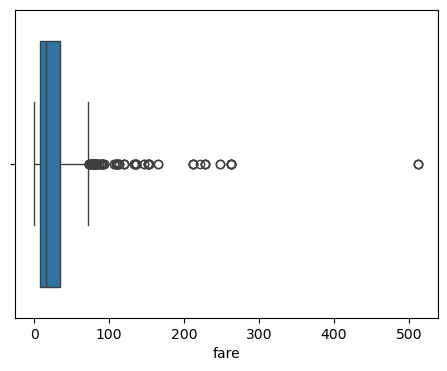

In [53]:
# boxplot for fare and age
plt.figure(figsize = (12,4))

plt.subplot(1,2,1)
sns.boxplot(x = df_clean["fare"])

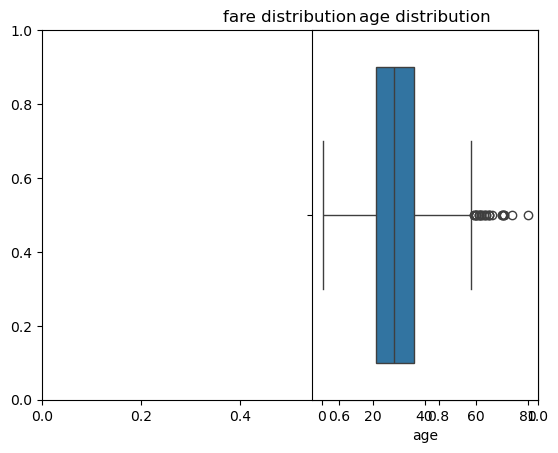

In [56]:
plt.title("fare distribution")

plt.subplot(1,2,2)
sns.boxplot(x = df_clean["age"])
plt.title("age distribution")

plt.show()

In [57]:
# optional: cap exxtreme fares using IQR method
Q1 = df_clean["fare"].quantile(0.25)
Q3 = df_clean["fare"].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5*IQR

print(f"fares above {upper_bound:.2f} are potential outliers.")
df_clean["fare_capped"] = df_clean["fare"].clip(upper = upper_bound)

fares above 73.42 are potential outliers.


### 1.2 Visualizations

### We will create: - Distribution plots - Categorical counts - Relationships (scatter, box) - Correlation heatmap

### 1.2.1 Univariate Plots

Text(0.5, 1.0, 'age distribution')

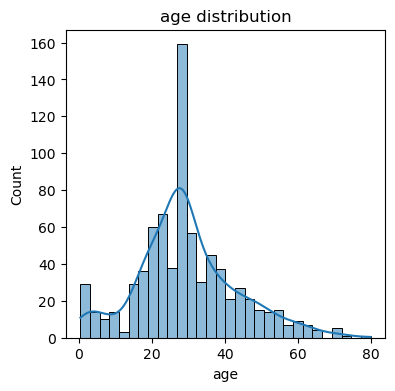

In [61]:
plt.figure(figsize = (14, 4))

# age distribution
plt.subplot(1, 3, 1)
sns.histplot(df_clean["age"], kde = True, bins = 30)
plt.title("age distribution")

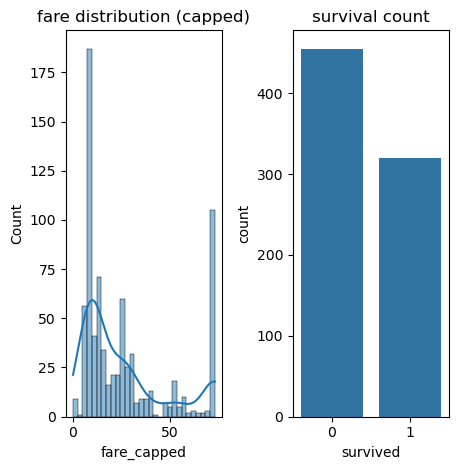

In [67]:
# fare distribution (capped)
plt.subplot(1,3,2)
sns.histplot(df_clean["fare_capped"], kde = True, bins = 30)
plt.title("fare distribution (capped)")

# survival rate
plt.subplot(1, 3, 3)
sns.countplot(x = "survived", data = df_clean)
plt.title("survival count")

plt.tight_layout()
plt.show()

### 1.2.2 Categorical Relationships

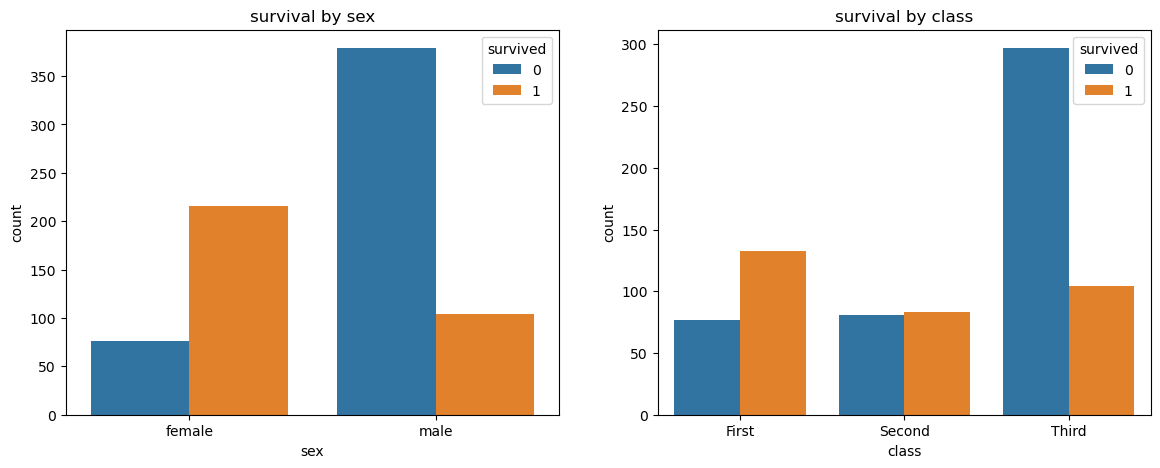

In [68]:
plt.figure(figsize = (14, 5))

# survival by sex
plt.subplot(1, 2, 1)
sns.countplot(x = "sex", hue = "survived", data = df_clean)
plt.title("survival by sex")

# survival by class
plt.subplot(1, 2, 2)
sns.countplot(x = "class", hue = "survived", data = df_clean)
plt.title("survival by class")

plt.show()

### 1.2.3 Numerical Relationships

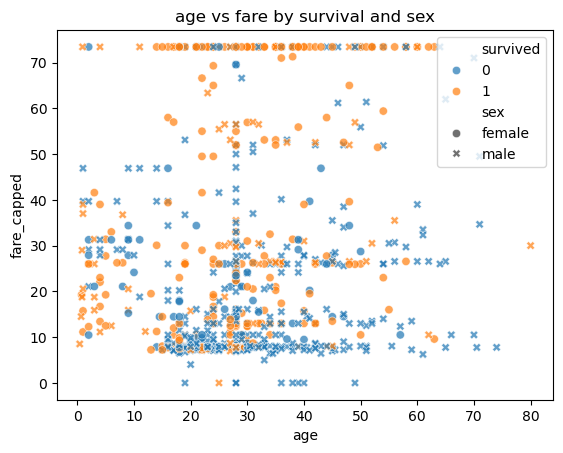

In [71]:
# age vs fare fare, colored by survival
sns.scatterplot(x = "age", y = "fare_capped", hue = "survived", style = "sex", alpha = 0.7, data = df_clean)
plt.title("age vs fare by survival and sex")
plt.show()

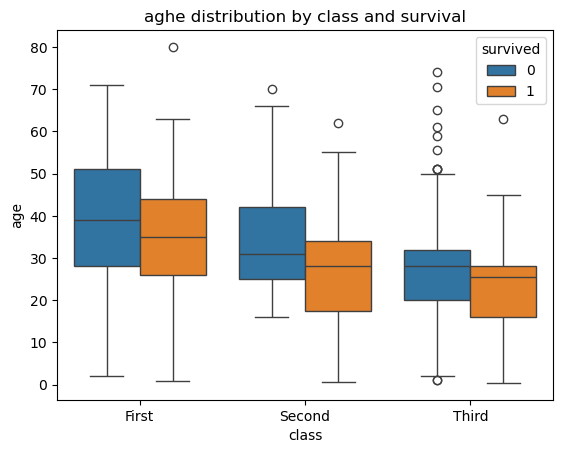

In [72]:
# boxplot: age by class
sns.boxplot(x = "class", y = "age", hue = "survived", data = df_clean)
plt.title("aghe distribution by class and survival")
plt.show()

### 1.2.4 Pairplot and Heatmap

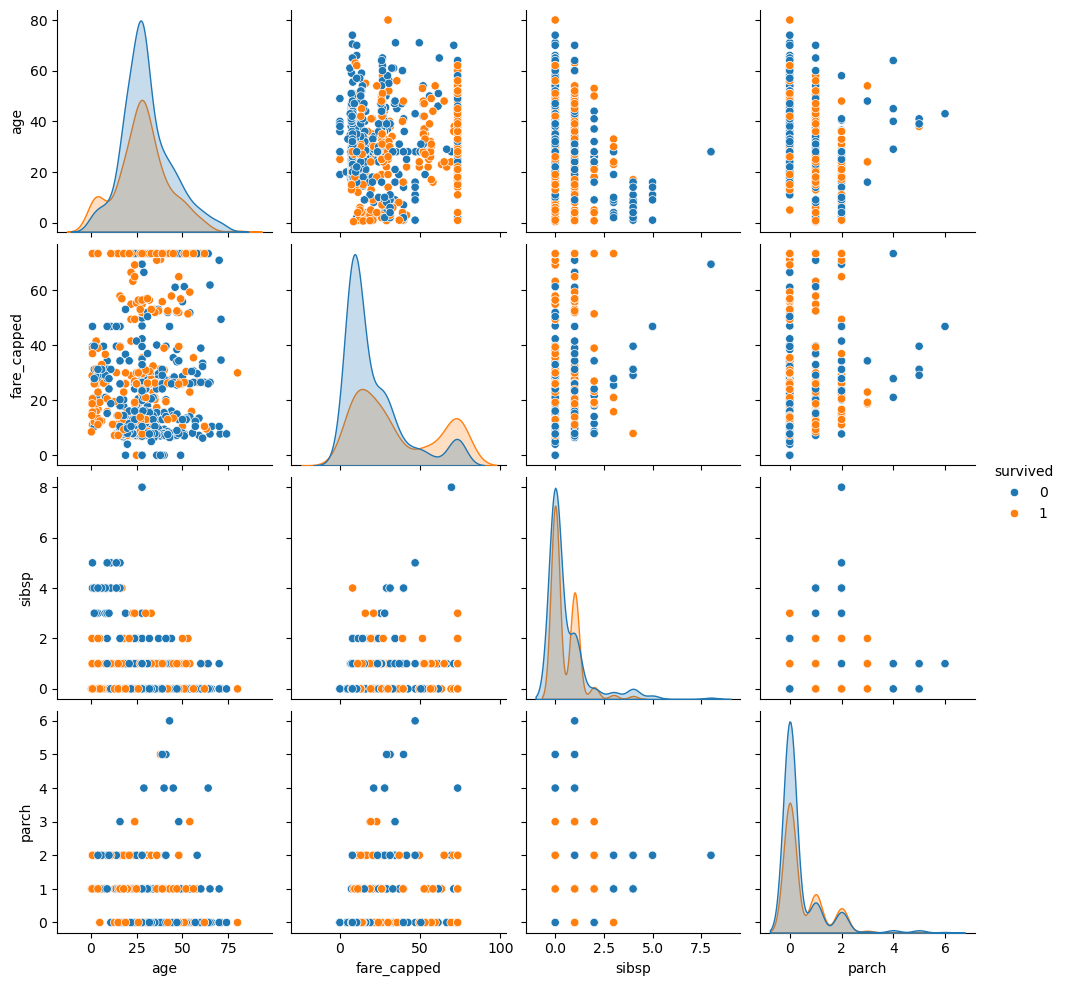

In [78]:
 # pairplot for key variables
sns.pairplot(df_clean, vars=['age', 'fare_capped', 'sibsp', 'parch'],
hue='survived', diag_kind='kde')
plt.show()

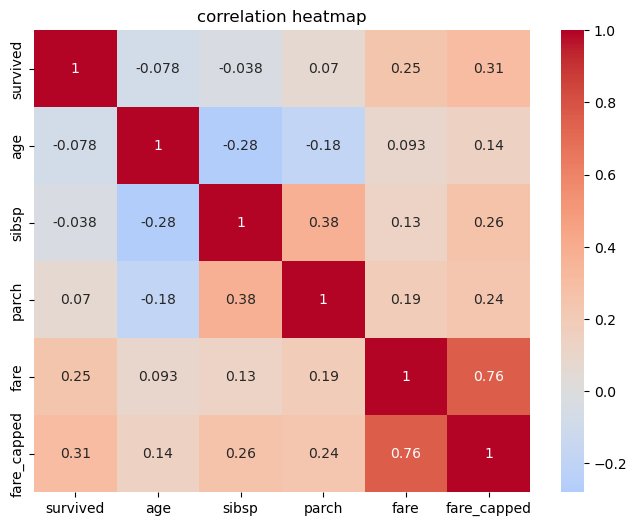

In [88]:
# correlation heatmap
plt.figure(figsize = (8, 6))
numeric_cols = df_clean.select_dtypes(include=np.number).columns
sns.heatmap(df_clean[numeric_cols].corr(), annot = True, cmap = "coolwarm", center = 0)
plt.title("correlation heatmap")
plt.show()